# Necessary Libraries

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_auc_score, roc_curve

In [2]:
df = pd.read_csv("WELFake_Dataset.csv")
df.head(6)


,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1
5,5,About Time! Christian Group Sues Amazon and SP...,All we can say on this one is it s about time ...,1


In [3]:
# Display dataset dimensions
print("Dataset Shape:", df.shape)

Dataset Shape: (72134, 4)


In [4]:
# Check column names
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['Unnamed: 0', 'title', 'text', 'label']


In [5]:
# Check data types
print("\nData Types:")
print(df.dtypes)


Data Types:
Unnamed: 0     int64
title         object
text          object
label          int64
dtype: object


# Data Preporcessing

In [6]:
# Check missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Unnamed: 0      0
title         558
text           39
label           0
dtype: int64


In [7]:
# Identify columns containing missing values
missing_columns = df.columns[df.isnull().any()]

# Fill missing values with the most frequent value in each column
for column in missing_columns:
    most_frequent_value = df[column].mode(dropna=True)[0]

    df[column] = df[column].fillna(most_frequent_value)

    print(f"Column: {column}")
    print(f"Most frequent value used: {most_frequent_value}")
    print("-" * 40)

Column: title
Most frequent value used: Factbox: Trump fills top jobs for his administration
----------------------------------------
Column: text
Most frequent value used:  
----------------------------------------


In [8]:
# Verify missing values after filling
print("\nMissing Values After Imputation:")
print(df.isnull().sum())

# Confirm total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())


Missing Values After Imputation:
Unnamed: 0    0
title         0
text          0
label         0
dtype: int64

Total Missing Values: 0


In [14]:
# Display the number of records for each label
label_counts = df["label"].value_counts().sort_index()

print("Target Label Distribution:")
print(label_counts)

# Calculate the percentage of each label
label_percentage = (
    df["label"].value_counts(normalize=True).sort_index() * 100
).round(2)

print("\nTarget Label Distribution (%):")
print(label_percentage)

Target Label Distribution:
label
0    35028
1    37106
Name: count, dtype: int64

Target Label Distribution (%):
label
0    48.56
1    51.44
Name: proportion, dtype: float64


# Exploratory Data Analysis

/tmp/ipykernel_1344/2557146990.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


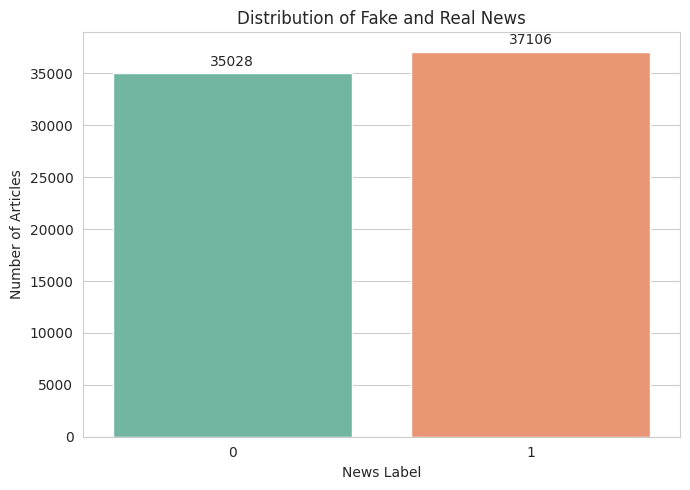

In [17]:
# Set the visualization style
sns.set_style("whitegrid")

# Count records for each target label
label_counts = df["label"].value_counts().sort_index()

# Create a bar chart
plt.figure(figsize=(7, 5))
ax = sns.barplot(
    x=label_counts.index.astype(str),
    y=label_counts.values,
    palette="Set2"
)

# Add chart title and axis labels
plt.title("Distribution of Fake and Real News")
plt.xlabel("News Label")
plt.ylabel("Number of Articles")

# Display the record count above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

# Display the chart
plt.tight_layout()
plt.show()

Title Length Statistics:


,title_length
count,72134.00
mean,76.95
std,25.03
min,1.00
25%,61.00
50%,73.00
75%,89.00
max,456.00


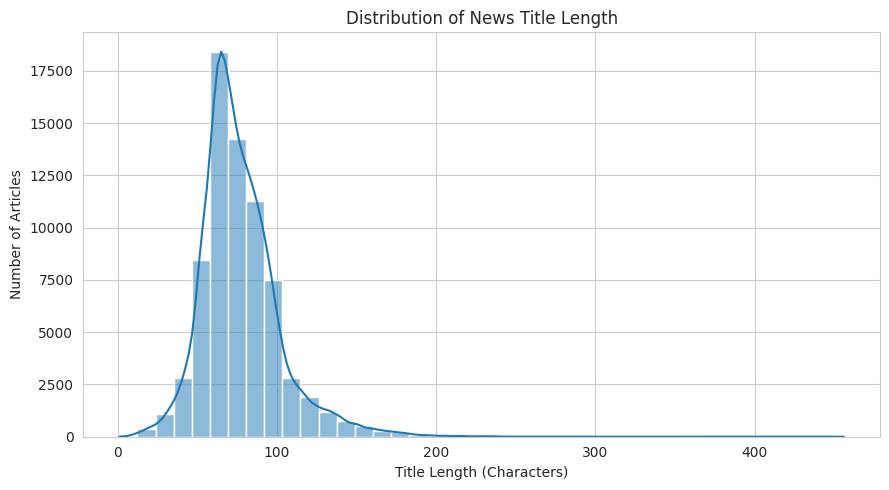

In [18]:
# Convert titles to strings and handle missing values temporarily
df["title_length"] = (
    df["title"].fillna("").astype(str).str.len()
)

# Display descriptive statistics for title length
print("Title Length Statistics:")
display(df["title_length"].describe().round(2))

# Visualize the distribution of title lengths
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="title_length",
    bins=40,
    kde=True
)

# Add chart title and axis labels
plt.title("Distribution of News Title Length")
plt.xlabel("Title Length (Characters)")
plt.ylabel("Number of Articles")

# Display the chart
plt.tight_layout()
plt.show()

Article Text Length Statistics:


,text_length
count,72134.00
mean,3268.39
std,3732.88
min,1.00
25%,1377.00
50%,2424.00
75%,4059.00
max,142961.00


/tmp/ipykernel_1344/692184777.py:12: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(


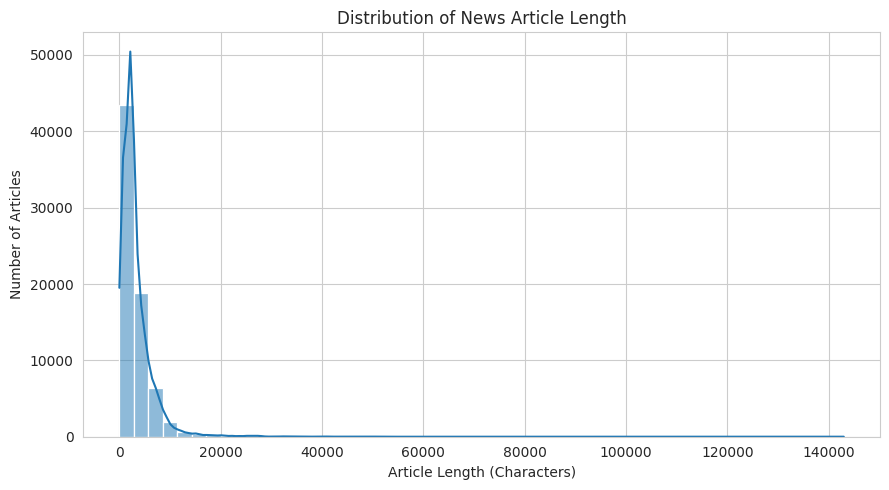

In [22]:
# Convert article text to strings and handle missing values temporarily
df["text_length"] = (
    df["text"].fillna("").astype(str).str.len()
)

# Display descriptive statistics for article length
print("Article Text Length Statistics:")
display(df["text_length"].describe().round(2))

# Plot the distribution of article lengths
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="text_length",
    bins=50,
    kde=True,
    palette="Set4"
)

# Add chart title and axis labels
plt.title("Distribution of News Article Length")
plt.xlabel("Article Length (Characters)")
plt.ylabel("Number of Articles")

# Display the chart
plt.tight_layout()
plt.show()


# Text Preprocessing

In [24]:
# Fill missing titles and article text with empty strings
df["title"] = df["title"].fillna("").astype(str)
df["text"] = df["text"].fillna("").astype(str)

# Combine the title and article body into one column
df["news_text"] = df["title"] + " " + df["text"]

# Remove extra whitespace from the combined text
df["news_text"] = df["news_text"].str.replace(
    r"\s+", " ", regex=True
).str.strip()

# Remove rows where the combined text is empty
df = df[df["news_text"].str.len() > 0].copy()

# Display sample combined news records
display(df[["title", "text", "news_text", "label"]].head())

# Display the updated dataset shape
print("Dataset Shape:", df.shape)


,title,text,news_text,label
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,1
1,Factbox: Trump fills top jobs for his administ...,Did they post their votes for Hillary already?,Factbox: Trump fills top jobs for his administ...,1
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,1
3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,"Bobby Jindal, raised Hindu, uses story of Chri...",0
4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",SATAN 2: Russia unvelis an image of its terrif...,1


Dataset Shape: (72134, 7)


In [25]:
# Select combined news text as the input feature
X = df["news_text"]

# Select the label column as the target
y = df["label"]

# Display the shapes of input and target variables
print("Input Feature Shape:", X.shape)
print("Target Variable Shape:", y.shape)

# Check the target label distribution
print("\nTarget Label Distribution:")
print(y.value_counts())


Input Feature Shape: (72134,)
Target Variable Shape: (72134,)

Target Label Distribution:
label
1    37106
0    35028
Name: count, dtype: int64


In [26]:
# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the number of records in each set
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# Display training label distribution
print("\nTraining Label Distribution:")
print(y_train.value_counts())

# Display testing label distribution
print("\nTesting Label Distribution:")
print(y_test.value_counts())


Training Samples: 57707
Testing Samples: 14427

Training Label Distribution:
label
1    29685
0    28022
Name: count, dtype: int64

Testing Label Distribution:
label
1    7421
0    7006
Name: count, dtype: int64


# TF-IDF Feature Engineering

In [28]:
# Initialize the TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=30000,  # Limit the vocabulary size
    ngram_range=(1, 2),  # Include single words and two-word phrases
    min_df=2,            # Ignore terms appearing in fewer than 2 documents
    max_df=0.95,         # Ignore terms appearing in more than 95% of documents
    sublinear_tf=True    # Reduce the impact of very frequent terms
)

# Learn vocabulary from training data and transform training text
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform test data using the training vocabulary
X_test_tfidf = tfidf.transform(X_test)

# Display the dimensions of the transformed data
print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

# Display the number of extracted text features
print("Total TF-IDF Features:", len(tfidf.get_feature_names_out()))


Training TF-IDF Shape: (57707, 30000)
Testing TF-IDF Shape: (14427, 30000)
Total TF-IDF Features: 30000


# Multinomial Naive Bayes

In [29]:
# Initialize the Multinomial Naive Bayes model
nb_model = MultinomialNB()

# Train the model using TF-IDF training features
nb_model.fit(X_train_tfidf, y_train)

# Predict labels for the test dataset
y_pred_nb = nb_model.predict(X_test_tfidf)

# Calculate the test accuracy
nb_accuracy = accuracy_score(y_test, y_pred_nb)

# Display the model accuracy
print("Multinomial Naive Bayes Accuracy:", round(nb_accuracy, 4))

# Display precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))


Multinomial Naive Bayes Accuracy: 0.8696

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.84      0.86      7006
           1       0.86      0.89      0.88      7421

    accuracy                           0.87     14427
   macro avg       0.87      0.87      0.87     14427
weighted avg       0.87      0.87      0.87     14427



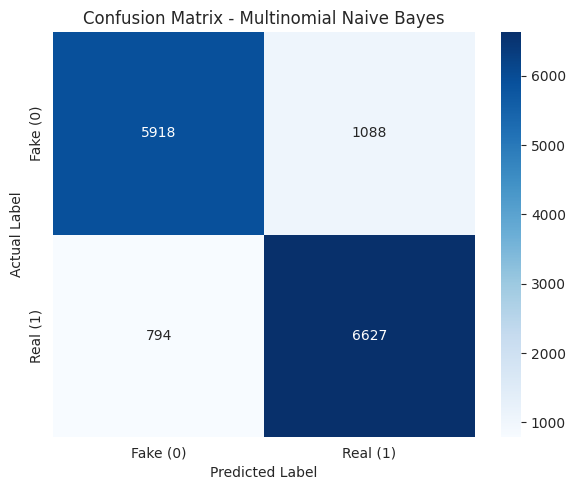

In [41]:
# Calculate the confusion matrix using test labels and predictions
cm_nb = confusion_matrix(y_test, y_pred_nb, labels=[0, 1])

# Plot the confusion matrix as a heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake (0)", "Real (1)"],
    yticklabels=["Fake (0)", "Real (1)"]
)

# Add chart title and axis labels
plt.title("Confusion Matrix - Multinomial Naive Bayes")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

# Display the chart
plt.tight_layout()
plt.show()


Multinomial Naive Bayes ROC-AUC: 0.9391


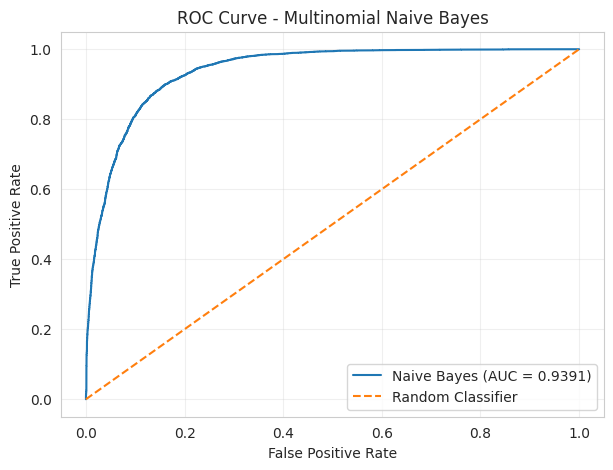

In [44]:
# Get the predicted probability for the positive class (label 1)
nb_scores = nb_model.predict_proba(X_test_tfidf)[:, 1]

# Calculate the ROC-AUC score
nb_auc = roc_auc_score(y_test, nb_scores)

# Display the ROC-AUC score
print("Multinomial Naive Bayes ROC-AUC:", round(nb_auc, 4))
fpr_nb, tpr_nb, thresholds_nb = roc_curve(y_test, nb_scores)
auc_nb = roc_auc_score(y_test, nb_scores)

# Plot ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr_nb, tpr_nb, label=f"Naive Bayes (AUC = {auc_nb:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Multinomial Naive Bayes")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

# Logistic Regression

In [30]:
# Initialize Logistic Regression with regularization
lr_model = LogisticRegression(
    C=1.0,
    max_iter=1000,
    random_state=42
)

# Train the model using TF-IDF training features
lr_model.fit(X_train_tfidf, y_train)

# Predict labels for the test dataset
y_pred_lr = lr_model.predict(X_test_tfidf)

# Calculate the test accuracy
lr_accuracy = accuracy_score(y_test, y_pred_lr)

# Display the model accuracy
print("Logistic Regression Accuracy:", round(lr_accuracy, 4))

# Display precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.9638

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.95      0.96      7006
           1       0.96      0.97      0.97      7421

    accuracy                           0.96     14427
   macro avg       0.96      0.96      0.96     14427
weighted avg       0.96      0.96      0.96     14427



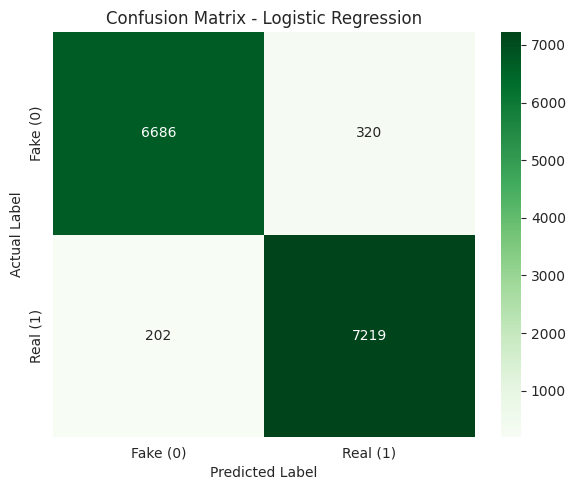

In [42]:
# Calculate the confusion matrix using test labels and predictions
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=[0, 1])

# Plot the confusion matrix as a heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Fake (0)", "Real (1)"],
    yticklabels=["Fake (0)", "Real (1)"]
)

# Add chart title and axis labels
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

# Display the chart
plt.tight_layout()
plt.show()


Linear SVM ROC-AUC: 0.9976


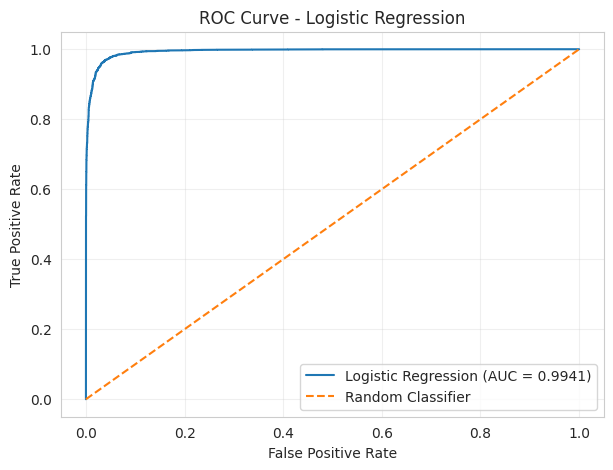

In [46]:
# Get the decision scores for the test dataset
svm_scores = svm_model.decision_function(X_test_tfidf)

# Calculate the ROC-AUC score for SVM
svm_auc = roc_auc_score(y_test, svm_scores)

# Display the ROC-AUC score
print("Linear SVM ROC-AUC:", round(svm_auc, 4))

# Define the missing lr_scores for Logistic Regression
lr_scores = lr_model.predict_proba(X_test_tfidf)[:, 1]

fpr_lr, tpr_lr, thresholds_lr = roc_curve(y_test, lr_scores)
auc_lr = roc_auc_score(y_test, lr_scores)

# Plot ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {auc_lr:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

# Support Vector Machine (SVM)

In [31]:
# Initialize the Linear SVM model
svm_model = LinearSVC(
    C=1.0,
    max_iter=3000,
    random_state=42
)

# Train the model using TF-IDF training features
svm_model.fit(X_train_tfidf, y_train)

# Predict labels for the test dataset
y_pred_svm = svm_model.predict(X_test_tfidf)

# Calculate the test accuracy
svm_accuracy = accuracy_score(y_test, y_pred_svm)

# Display the model accuracy
print("Linear SVM Accuracy:", round(svm_accuracy, 4))

# Display precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))


Linear SVM Accuracy: 0.9765

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.97      0.98      7006
           1       0.97      0.98      0.98      7421

    accuracy                           0.98     14427
   macro avg       0.98      0.98      0.98     14427
weighted avg       0.98      0.98      0.98     14427



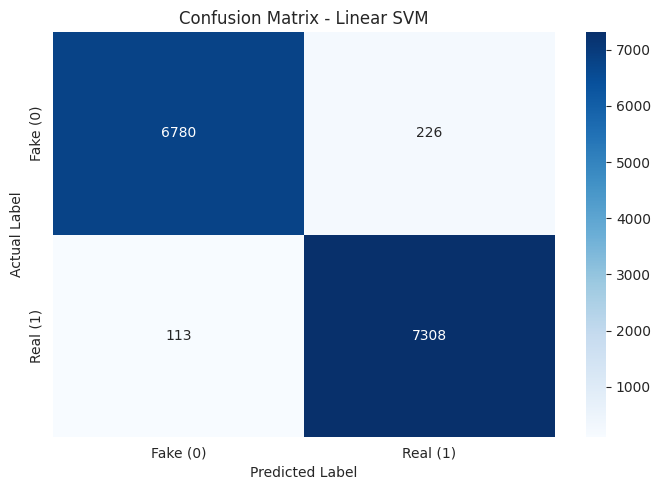

In [36]:
# Calculate the confusion matrix using test labels and predictions
cm = confusion_matrix(y_test, y_pred_svm)

# Create a heatmap to visualize the confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake (0)", "Real (1)"],
    yticklabels=["Fake (0)", "Real (1)"]
)

# Add chart title and axis labels
plt.title("Confusion Matrix - Linear SVM")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

# Display the chart
plt.tight_layout()
plt.show()


Linear SVM ROC-AUC: 0.9976


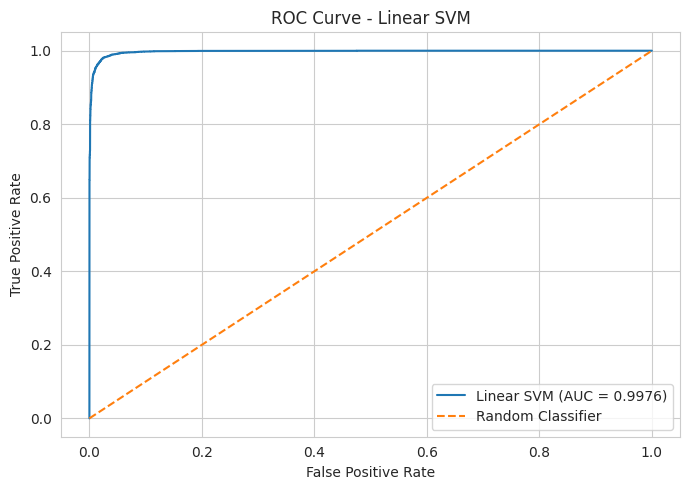

In [40]:
# Obtain decision scores for the test dataset
svm_scores = svm_model.decision_function(X_test_tfidf)

# Calculate the ROC-AUC score
svm_auc = roc_auc_score(y_test, svm_scores)

# Display the ROC-AUC score
print("Linear SVM ROC-AUC:", round(svm_auc, 4))
# Calculate false positive rate and true positive rate
fpr, tpr, thresholds = roc_curve(y_test, svm_scores)

# Plot the ROC curve
plt.figure(figsize=(7, 5))
plt.plot(
    fpr,
    tpr,
    label=f"Linear SVM (AUC = {svm_auc:.4f})"
)

# Add a baseline for random classification
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

# Add chart title and axis labels
plt.title("ROC Curve - Linear SVM")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")

# Display the chart
plt.tight_layout()
plt.show()

In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
# Store the predictions generated by each model
model_predictions = {
    "Multinomial Naive Bayes": y_pred_nb,
    "Logistic Regression": y_pred_lr,
    "Linear SVM": y_pred_svm
}

# Create a list to store evaluation results
comparison_results = []

# Calculate performance metrics for every model
for model_name, predictions in model_predictions.items():

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

# Convert the results into a DataFrame
model_comparison_df = pd.DataFrame(comparison_results)

# Sort the models by F1-score
model_comparison_df = model_comparison_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

# Display the comparison table
display(model_comparison_df.round(4))


,Model,Accuracy,Precision,Recall,F1-Score
0,Linear SVM,0.9765,0.9700,0.9848,0.9773
1,Logistic Regression,0.9638,0.9576,0.9728,0.9651
2,Multinomial Naive Bayes,0.8696,0.8590,0.8930,0.8757


In [48]:
os.makedirs("models", exist_ok=True)

# Save the trained Linear SVM model and TF-IDF vectorizer
joblib.dump(svm_model, "models/best_fake_news_svm_model.pkl")
joblib.dump(tfidf, "models/tfidf_vectorizer.pkl")

# Confirm that the files are saved
print("Best model and TF-IDF vectorizer saved successfully!")
print("Model: models/best_fake_news_svm_model.pkl")
print("Vectorizer: models/tfidf_vectorizer.pkl")

Best model and TF-IDF vectorizer saved successfully!
Model: models/best_fake_news_svm_model.pkl
Vectorizer: models/tfidf_vectorizer.pkl


# Prediction of Fake or Real

In [49]:
svm_model = joblib.load("models/best_fake_news_svm_model.pkl")

# Load the saved TF-IDF vectorizer
tfidf = joblib.load("models/tfidf_vectorizer.pkl")

# Confirm successful loading
print("Linear SVM model loaded successfully!")
print("TF-IDF vectorizer loaded successfully!")

Linear SVM model loaded successfully!
TF-IDF vectorizer loaded successfully!


In [51]:
# Enter the news title
news_title = "Scientists Confirm That Earth Revolves Around the Sun"

# Enter the news article text
news_text = """
Scientists have explained that Earth revolves around the Sun
as part of the solar system. Earth takes approximately 365 days
to complete one revolution around the Sun. This scientific
understanding is supported by astronomical observations and research.
"""

# Combine title and article text
new_news = news_title + " " + news_text

# Clean extra whitespace
new_news = " ".join(new_news.split())

# Display the input
print("News Title:", news_title)
print("\nNews Text:", news_text)
print("\nCombined News Text:", new_news)

News Title: Scientists Confirm That Earth Revolves Around the Sun

News Text: 
Scientists have explained that Earth revolves around the Sun
as part of the solar system. Earth takes approximately 365 days
to complete one revolution around the Sun. This scientific
understanding is supported by astronomical observations and research.


Combined News Text: Scientists Confirm That Earth Revolves Around the Sun Scientists have explained that Earth revolves around the Sun as part of the solar system. Earth takes approximately 365 days to complete one revolution around the Sun. This scientific understanding is supported by astronomical observations and research.


In [52]:
# Convert the new news text using the saved TF-IDF vectorizer
news_features = tfidf.transform([new_news])

# Display the feature matrix shape
print("News converted into TF-IDF features.")
print("Feature shape:", news_features.shape)

News converted into TF-IDF features.
Feature shape: (1, 30000)


In [53]:
# Predict the label using the trained Linear SVM model
prediction = svm_model.predict(news_features)[0]

# Display the prediction
if prediction == 0:
    print("Prediction: FAKE NEWS")
elif prediction == 1:
    print("Prediction: REAL NEWS")
else:
    print("Unknown label:", prediction)

Prediction: REAL NEWS
